# Sensibilidad de Rank-1 al número de identidades distractoras

## Fase 1. Preparación y verificación de datos

**Objetivo:** cuantificar la sensibilidad al tamaño de galería en CLIP/DINOv2 E1–E4 sin entrenar ni seleccionar modelos nuevos. **Pregunta:** ¿cómo cambia la probabilidad de recuperar la identidad correcta al incluir más rivales de la misma especie? **Hipótesis:** Rank-1 esperado no aumenta al añadir rivales de una población fija.

**Intervención:** muestreo uniforme sin reemplazo de identidades rivales, conservando todas sus fotografías y todos los positivos de la consulta. **Controles:** mismos checkpoints, consultas, orden de ranking y población por dominio; público v1 inmutable (277 fotos/60 identidades) y PetTrace v6 (502/50) siempre separados. **Muestra:** todas las consultas publicadas de las ocho condiciones. No se vuelven a limpiar datos ni se usan identidades de test para seleccionar checkpoints.

**Métricas:** Rank-1 esperado exacto por especie y tamaño de galería; consulta fotográfica ponderada uniformemente. No se estima mAP a partir de rangos de identidad. **Selección/entrenamiento:** ninguno. Diseño retrospectivo fijado en este cuaderno antes de calcular curvas.

Esto varía distractores dentro de la galería observada; no incorpora animales externos ni demuestra búsqueda abierta o generalización entre sesiones. No es una nueva prueba independiente. La formulación combinatoria y los tamaños de galería son decisiones de análisis de este estudio.

In [ ]:
# Runtime guard added after the recorded execution; historical outputs are unchanged.
import sys
if not (3, 11) <= sys.version_info[:2] < (3, 14):
    raise RuntimeError("Python 3.11–3.13 required")


In [1]:
from pathlib import Path
from math import comb
import hashlib, json, os
import numpy as np
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src/pettrace').exists()
OUT=ROOT/'reports/distractor-sensitivity-20261120'
OUT.mkdir(parents=True,exist_ok=True)
conditions={}
for domain in ('public','private'):
    base=ROOT/'reports/clip-e1-e2-v6-20261119-verified'
    clip=base/'public_test' if domain=='public' else base
    paths={
        'CLIP E1':clip/'baseline_e1/scores.json',
        'CLIP E2':clip/'evaluation-input.json',
        'CLIP E3':OUT/'inputs'/domain/'evaluation.json',
        'CLIP E4':ROOT/'reports/e4-sampling-session/baseline'/domain/'evaluation.json',
    }
    for stage,folder in [('E1','raw'),('E2','frozen'),('E3','mlp-46'),('E4','mlp_lora-47')]:
        paths['DINOv2 '+stage]=ROOT/'reports/dino-sequential/20261119-v1'/folder/domain/'evaluation-input.json'
    expected=None
    for model,path in paths.items():
        payload=json.loads(path.read_text())
        result=payload.get('result',payload)
        rows=result['test']['per_query']
        assert len(rows)==(277 if domain=='public' else 502)
        signature=sorted((r['animal'],r['species'],Path(r['photo']).stem) for r in rows)
        if expected is None: expected=signature
        assert signature==expected,(domain,model,'query mismatch')
        sizes={'cat':34,'dog':26} if domain=='public' else {'cat':17,'dog':33}
        assert all(r['gallery_animals']==sizes[r['species']] and 1<=r['rank']<=r['gallery_animals'] for r in rows)
        actual=sum(r['rank']==1 for r in rows)/len(rows)
        assert abs(actual-result['test']['global']['rank1'])<1e-10
        conditions[domain,model]={'rows':rows,'path':str(path.relative_to(ROOT)),'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
manifest=[{'domain':d,'model':m,**{k:v for k,v in item.items() if k!='rows'}} for (d,m),item in conditions.items()]
(OUT/'input-manifest.json').write_text(json.dumps(manifest,indent=2))
print('Verified 16 conditions, matching queries and species-specific gallery sizes.')

Verified 16 conditions, matching queries and species-specific gallery sizes.


## Fase 2. Representación y entrenamiento

Se reutiliza el rango por identidad registrado, que agrega el máximo de similitud de las fotografías del animal. No hay inferencia ni entrenamiento nuevos. CLIP E4 es el ganador histórico; DINO E3/E4 son las semillas 46/47 seleccionadas por validación.

Para una consulta con rango completo r entre N identidades, existen r−1 rivales por encima de la identidad correcta y N−r por debajo. Al elegir d rivales uniformemente sin reemplazo, la probabilidad exacta de Rank-1 es C(N−r,d)/C(N−1,d), o cero si d>N−r. El promedio sobre consultas integra exactamente todos los subconjuntos posibles; no es una simulación ni un intervalo de confianza. Los empates conservan el orden del evaluador publicado.

Las comprobaciones siguientes comparan la fórmula con enumeración exhaustiva en ejemplos pequeños y verifican que la galería completa reproduce cada control publicado.

In [2]:
def rank1_probability(rank, identities, distractors):
    if not (1<=rank<=identities and 0<=distractors<identities):
        raise ValueError('Invalid rank or gallery size')
    return comb(identities-rank,distractors)/comb(identities-1,distractors) if distractors<=identities-rank else 0.0
from itertools import combinations
for N in range(2,9):
    for r in range(1,N+1):
        for d in range(N):
            subsets=list(combinations(range(1,N),d))
            brute=sum(all(i>=r for i in subset) for subset in subsets)/len(subsets)
            assert abs(rank1_probability(r,N,d)-brute)<1e-12
        assert rank1_probability(r,N,N-1)==float(r==1)
        values=[rank1_probability(r,N,d) for d in range(N)]
        assert all(a>=b for a,b in zip(values,values[1:]))
print('Exhaustive combinatorial checks passed for N=2..8.')

Exhaustive combinatorial checks passed for N=2..8.


## Fase 3. Evaluación y análisis

Curvas completas desde 1 rival hasta todos los rivales disponibles, separadas por especie y dominio. Los tamaños comunes permiten comparar encoders sin confundir especies con galerías distintas. Los resultados son descriptivos y condicionales a esta población; reducir la galería aumenta mecánicamente la facilidad del problema. No se extrapola a cientos de animales ni se interpreta la monotonía como un descubrimiento del modelo.

Publicación obligatoria en https://ml.pettrace.app. Los archivos se guardan antes de publicar; reejecutar permite reintentar publicación sin entrenamiento. Registro de modelo y promoción de alias no se realizan.

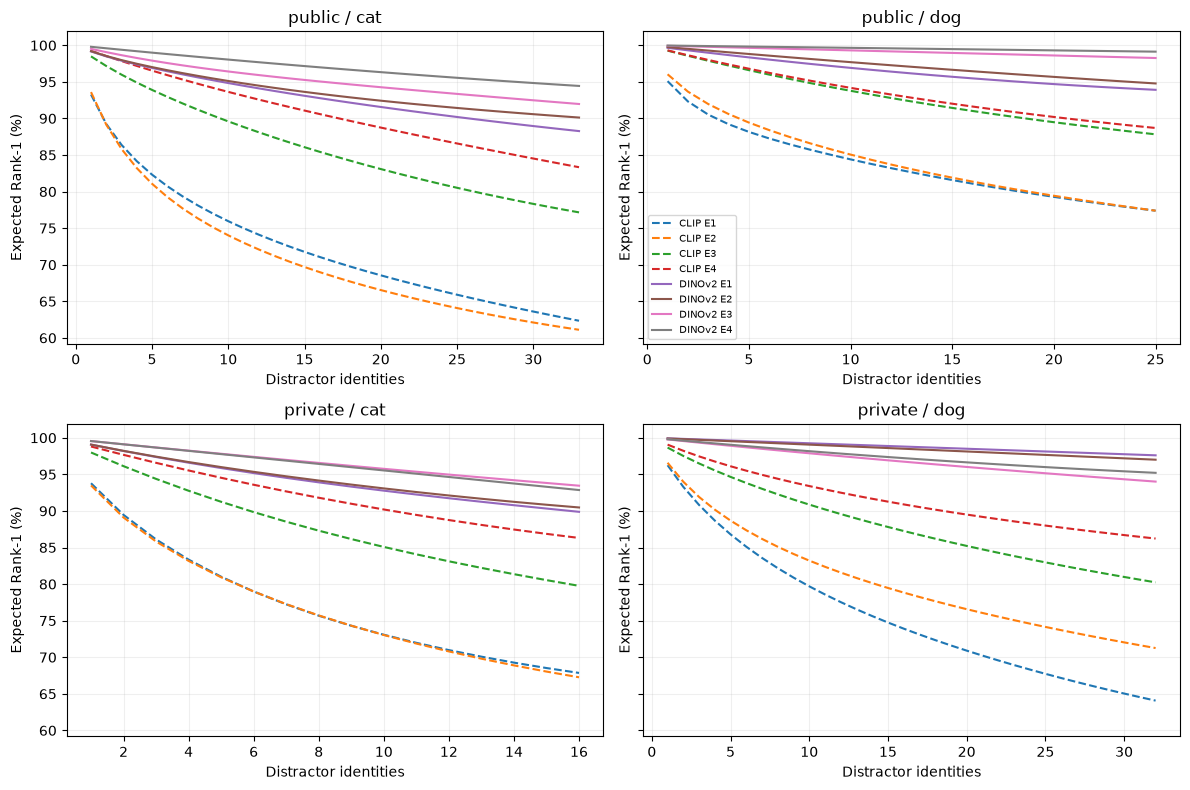

public
CLIP E4 cat [(1, 99.25), (5, 96.54), (10, 93.63), (33, 83.33)]
CLIP E4 dog [(1, 99.3), (5, 96.8), (10, 94.18), (25, 88.7)]
DINOv2 E4 cat [(1, 99.79), (5, 98.99), (10, 98.05), (33, 94.44)]
DINOv2 E4 dog [(1, 99.97), (5, 99.83), (10, 99.65), (25, 99.13)]
private
CLIP E4 cat [(1, 98.81), (5, 94.53), (10, 90.2), (16, 86.31)]
CLIP E4 dog [(1, 99.06), (5, 96.11), (10, 93.4), (32, 86.23)]
DINOv2 E4 cat [(1, 99.55), (5, 97.77), (10, 95.54), (16, 92.86)]
DINOv2 E4 dog [(1, 99.8), (5, 99.05), (10, 98.17), (32, 95.21)]


In [3]:
curves=[]
for (domain,model),item in conditions.items():
    for species in ('cat','dog'):
        rows=[r for r in item['rows'] if r['species']==species]
        N=rows[0]['gallery_animals']
        for d in range(1,N):
            value=float(np.mean([rank1_probability(r['rank'],N,d) for r in rows]))
            curves.append(dict(domain=domain,model=model,species=species,distractors=d,gallery_identities=d+1,queries=len(rows),expected_rank1=value))
        assert abs(value-np.mean([r['rank']==1 for r in rows]))<1e-12
(OUT/'curves.json').write_text(json.dumps(curves,indent=2))
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(12,8),sharey=True)
for ax,(domain,species) in zip(axes.flat,[(d,s) for d in ('public','private') for s in ('cat','dog')]):
    for model in sorted({r['model'] for r in curves}):
        points=[r for r in curves if (r['domain'],r['species'],r['model'])==(domain,species,model)]
        ax.plot([r['distractors'] for r in points],[100*r['expected_rank1'] for r in points],label=model,linestyle='--' if model.startswith('CLIP') else '-')
    ax.set_title(f'{domain} / {species}');ax.set_xlabel('Distractor identities');ax.set_ylabel('Expected Rank-1 (%)');ax.grid(alpha=.2)
axes[0,1].legend(fontsize=7);fig.tight_layout();fig.savefig(OUT/'curves.png',dpi=180);plt.show()
for domain in ('public','private'):
    print(domain)
    for model in ('CLIP E4','DINOv2 E4'):
        for species in ('cat','dog'):
            points=[r for r in curves if (r['domain'],r['species'],r['model'])==(domain,species,model)]
            print(model,species,[(r['distractors'],round(100*r['expected_rank1'],2)) for r in points if r['distractors'] in (1,5,10,points[-1]['distractors'])])

In [4]:
from dotenv import load_dotenv
load_dotenv(ROOT/'.env')
import mlflow
mlflow.set_tracking_uri('https://ml.pettrace.app')
for name in ('MLFLOW_TRACKING_USERNAME','MLFLOW_TRACKING_PASSWORD'):
    assert os.environ.get(name),f'Missing {name}'
mlflow.set_experiment('pettrace-reid-eval')
receipt=OUT/'publication.json'
if receipt.exists():
    run_id=json.loads(receipt.read_text())['run_id']
else:
    run_id=mlflow.MlflowClient().create_run(mlflow.get_experiment_by_name('pettrace-reid-eval').experiment_id,tags={'mlflow.runName':'CLIP DINO E1-E4 exact distractor sensitivity 20261120','experiment':'distractor-sensitivity','analysis.scope':'existing-gallery-only'}).info.run_id
    receipt.write_text(json.dumps({'run_id':run_id,'published':False},indent=2))
with mlflow.start_run(run_id=run_id):
    mlflow.log_params({'protocol':'exact uniform rival-identity subsampling','domains':'public and private separately','conditions':16,'training':False,'external_distractors':False,'session_disjoint':False,'model_registration':False})
    for path in (OUT/'input-manifest.json',OUT/'curves.json',OUT/'curves.png',ROOT/'notebooks/distractor_sensitivity.ipynb'):
        mlflow.log_artifact(str(path),artifact_path='analysis')
    mlflow.log_metric('analysis.conditions',16)
assert mlflow.MlflowClient().get_run(run_id).info.status=='FINISHED'
receipt.write_text(json.dumps({'run_id':run_id,'published':True,'url':f'https://ml.pettrace.app/#/experiments/3/runs/{run_id}'},indent=2))
print('Published:',json.loads(receipt.read_text())['url'])

2026/11/20 08:01:39 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/alessandro/Develop/personal/pettrace-ml/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


🏃 View run CLIP DINO E1-E4 exact distractor sensitivity 20261120 at: https://ml.pettrace.app/#/experiments/3/runs/b85b07563d0341ffbf4672ad2433274c
🧪 View experiment at: https://ml.pettrace.app/#/experiments/3


Published: https://ml.pettrace.app/#/experiments/3/runs/b85b07563d0341ffbf4672ad2433274c
